## MELISSA MERMOURI 

#  Analyse de spams avec des techniques de classification bayésienne naïve
Nous cherchons à diagnostiquer si des emails sont des spams avec une classification bayésienne naïve. Il s'agit d'un cas très classique d'application de cette technique de classification.

L’ensemble des données est issu de 960 emails réels prétraités de la base Ling-spam (anciennement accessible à cette adresse http://csmining.org/index.php/ling-spam-datasets.html). Ces emails sont en langue anglaise.

## Données

L’ensemble des données se divise en 700 emails exemples d’apprentissage et 260 emails exemples de test, chaque sous-ensemble étant par moitié des spams et des non-spams.

Ces emails ont été pré-traités : élimination de mots non signifiants (the, and, ...) ; nombres et ponctuations supprimées ; regroupement de mots de même racine avec des terminaisons différentes (include, includes, included, ...) ; ...

## Étape 1 : Chargement des données et création de la matrice train_matrix

In [1]:
import numpy as np

# Paramètres du jeu d'apprentissage
numTrainDocs = 700
numTokens = 2500

# Chargement des fichiers
M = np.loadtxt('train-features.txt', dtype=int)
train_labels = np.loadtxt('train-labels.txt', dtype=int)

# Initialisation de la matrice creuse
train_matrix = np.zeros((numTrainDocs, numTokens))

# Remplissage de la matrice avec des 1 si le mot est present ,0 sinon 

train_matrix[M[:, 0] - 1, M[:, 1] - 1] = 1


print("Dimensions de train_matrix :", train_matrix.shape)
print("Dimensions de train_labels :", train_labels.shape)

print("un bout de la matrice :", train_matrix[:5, :25].astype(int))
mots_presents_mail_1 = np.where(train_matrix[0] == 1)[0]
print("Indices des mots présents dans le mail 1 :", mots_presents_mail_1)


Dimensions de train_matrix : (700, 2500)
Dimensions de train_labels : (700,)
un bout de la matrice : [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
Indices des mots présents dans le mail 1 : [  18   44   49   74   84  138  199  350  351  512  563  742  776 1130
 1276 1638 1763 1815 1867]


# Étape 2 : Calcul des probabilités

Soit 

* $P(w_i \mid S)$ (la probabilité du mot sachant que c'est un Spam) .
* $P(w_i \mid \overline{S})$ (la probabilité du mot sachant que c'est un mail normal) .

In [2]:

nb_spam = np.sum(train_labels == 1)
nb_non_spam = np.sum(train_labels == 0)
print(f"nombre de spams = {nb_spam}, Nombre de mail normal = {nb_non_spam}")

# Probabilités a priori P(S) et P(non S)
p_spam = nb_spam / numTrainDocs
p_non_spam = nb_non_spam / numTrainDocs
print(f"P(S) = {p_spam:.4f} | P(non S) = {p_non_spam:.4f}")


# on compte la présence de chaque mot dans les spam et mails normaux
mots_dans_spams = np.sum(train_matrix[train_labels == 1], axis=0)
mots_dans_non_spams = np.sum(train_matrix[train_labels == 0], axis=0)
print("5 premiers comptages (spams) :", mots_dans_spams[:5])
print("5 premiers comptages (non-spams) :", mots_dans_non_spams[:5])


# Calcul des probabilités  avec lissage de Laplace 
prob_mot_sachant_s  = (mots_dans_spams + 1)     / (nb_spam + 2)
prob_mot_sachant_ns = (mots_dans_non_spams + 1) / (nb_non_spam + 2)
print("5 premières P(mot | S) :", np.round(prob_mot_sachant_s[:5], 4))
print("5 premières P(mot | non S) :", np.round(prob_mot_sachant_ns[:5], 4))


nombre de spams = 350, Nombre de mail normal = 350
P(S) = 0.5000 | P(non S) = 0.5000
5 premiers comptages (spams) : [185. 166. 130.   5.  70.]
5 premiers comptages (non-spams) : [136. 113.  73. 241.  30.]
5 premières P(mot | S) : [0.5284 0.4744 0.3722 0.017  0.2017]
5 premières P(mot | non S) : [0.3892 0.3239 0.2102 0.6875 0.0881]


# Étape 3 : Prédiction sur les données de test et évaluation

### Calculer les scores avec np.log et prédire

In [3]:
nb_test_docs = 260 

# Chargement des caractéristiques de test et des vraies étiquettes
M_test = np.loadtxt('test-features.txt')
test_labels = np.loadtxt('test-labels.txt')

# Création de la matrice de test 
test_matrix = np.zeros((nb_test_docs, numTokens))
for ligne in M_test:
    num_mail = int(ligne[0]) - 1   
    num_mot = int(ligne[1]) - 1
    test_matrix[num_mail, num_mot] = 1
print("Forme de test_matrix :", test_matrix.shape)
print("Forme de test_labels :", test_labels.shape)


# Log des probabilités a priori
log_prior_diff = np.log(p_spam) - np.log(p_non_spam)

# Poids de chaque mot du dictionnaire 
poids_mots = np.log(prob_mot_sachant_s) - np.log(prob_mot_sachant_ns)

# Score de chacun des 260 e-mails de test
scores_test = log_prior_diff + test_matrix @ poids_mots

# 1 si score > 0 (Spam), sinon 0 (Non-Spam)
predictions = (scores_test > 0).astype(int)

print("5 premiers scores :", np.round(scores_test[:5], 2))
print("5 premières prédictions :", predictions[:5])
print("Nombre de spams prédits :", np.sum(predictions == 1))
print("Nombre de mails normaux prédits :", np.sum(predictions == 0))



Forme de test_matrix : (260, 2500)
Forme de test_labels : (260,)
5 premiers scores : [-40.   -13.73 -93.03 -21.62 -12.42]
5 premières prédictions : [0 0 0 0 0]
Nombre de spams prédits : 135
Nombre de mails normaux prédits : 125


### Matrice de confusion et métriques d'évaluation

Matrice de confusion :

                 Prédit 0 (Normal)  Prédit 1 (Spam)
Réel 0 (Normal)                125                5
Réel 1 (Spam)                    0              130

Accuracy  : 0.9808
Précision : 0.9630
Rappel    : 1.0000
F1-score  : 0.9811


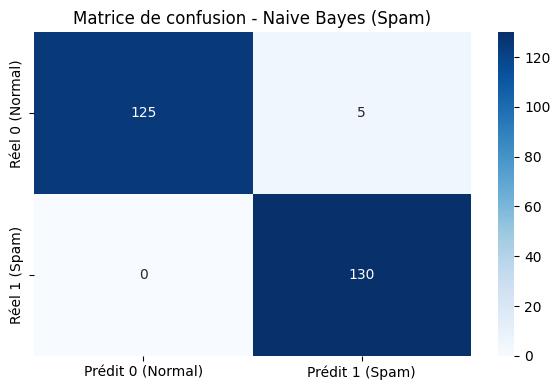

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Matrice de confusion 
y_true = test_labels.astype(int)
cm = confusion_matrix(y_true, predictions)

cm_df = pd.DataFrame(
    cm,
    index=["Réel 0 (Normal)", "Réel 1 (Spam)"],
    columns=["Prédit 0 (Normal)", "Prédit 1 (Spam)"]
)
print("Matrice de confusion :\n")
print(cm_df)

# Métriques globales 
print(f"\nAccuracy  : {accuracy_score(y_true, predictions):.4f}")
print(f"Précision : {precision_score(y_true, predictions):.4f}")
print(f"Rappel    : {recall_score(y_true, predictions):.4f}")
print(f"F1-score  : {f1_score(y_true, predictions):.4f}")

# Affichage graphique 
plt.figure(figsize=(6, 4))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de confusion - Naive Bayes (Spam)")
plt.tight_layout()
plt.show()


#### Commentaires

le modèle est **très performant** : sur les **260** e-mails de test, il en classe **255 correctement** (soit environ **98,1 %** de bonnes réponses) et ne fait que **5 erreurs** (toutes des fausses alertes sur des mails normaux, aucun spam raté).

* **125 (`Réel 0` / `Prédit 0` `) :** 125 courriers normaux ont bien été reconnus comme normaux.


* **5 (`Réel 0` / `Prédit 1`) :** 5 vrais courriers normaux ont été classés à tort comme spams .


* **0 (`Réel 1` / `Prédit 0` ) :** **0 spam raté** — tous les vrais spams du jeu de test ont été détectés.


* **130 (`Réel 1` / `Prédit 1`) :** 130 vrais spams ont été correctement identifiés comme spams.

# Étape 4 : Comparaison avec GaussianNB de scikit-learn

Matrice de confusion - GaussianNB :

                 Prédit 0 (Normal)  Prédit 1 (Spam)
Réel 0 (Normal)                124                6
Réel 1 (Spam)                    2              128

--- Comparaison des deux modèles ---
modèle binaire  -> Accuracy : 0.9808 | F1-score : 0.9811
GaussianNB    -> Accuracy : 0.9692 | F1-score : 0.9697


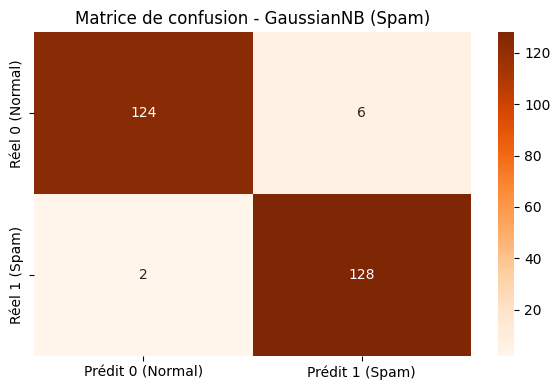

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

# Création et entraînement du modèle GaussianNB sur les données d'apprentissage
modele_gaussien = GaussianNB()
modele_gaussien.fit(train_matrix, train_labels.ravel())

# Prédictions sur les 260 mails de test
predictions_gaussien = modele_gaussien.predict(test_matrix)

# Matrice de confusion pour GaussianNB
y_reel = test_labels.astype(int).ravel()
cm_gaussien = confusion_matrix(y_reel, predictions_gaussien)

tableau_cm_gaussien = pd.DataFrame(
    cm_gaussien,
    index=["Réel 0 (Normal)", "Réel 1 (Spam)"],
    columns=["Prédit 0 (Normal)", "Prédit 1 (Spam)"]
)
print("Matrice de confusion - GaussianNB :\n")
print(tableau_cm_gaussien)

# Comparaison des performances entre notre modèle et GaussianNB
print("\n--- Comparaison des deux modèles ---")
print(f"modèle binaire  -> Accuracy : {accuracy_score(y_reel, predictions):.4f} | F1-score : {f1_score(y_reel, predictions):.4f}")
print(f"GaussianNB    -> Accuracy : {accuracy_score(y_reel, predictions_gaussien):.4f} | F1-score : {f1_score(y_reel, predictions_gaussien):.4f}")

#Affichage graphique de la matrice de confusion de GaussianNB
plt.figure(figsize=(6, 4))
sns.heatmap(tableau_cm_gaussien, annot=True, fmt="d", cmap="Oranges")
plt.title("Matrice de confusion - GaussianNB (Spam)")
plt.tight_layout()
plt.show()

### Commentaire

> Les deux modèles obtiennent d'excellentes performances sur les 260 mails de test, mais **notre modèle bayésien naïf est légèrement supérieur** à `GaussianNB` :
> * **Performance globale :** Notre modèle atteint **98,08 % d'accuracy** (et **0,9811 de F1-score**), contre **96,92 % d'accuracy** (et **0,9697 de F1-score**) pour `GaussianNB`.
> * **Analyse des erreurs :** Notre modèle ne fait que **5 erreurs** au total (5 faux positifs, **0 faux négatif** : tous les spams sont détectés). `GaussianNB` fait **8 erreurs** : **6 faux positifs** (6 mails normaux classés en spam) et **2 faux négatifs** (2 spams non détectés).
> * **Explication théorique :** Nos variables d'entrée sont **binaires** (`0` ou `1` pour la présence/absence d'un mot) et calculées avec un **lissage de Laplace**, ce qui correspond bien à la modélisation de présence de mots en classification de texte. À l'inverse, `GaussianNB` suppose que chaque variable suit une **loi normale (continue)**, une hypothèse moins naturelle sur des indicateurs binaires de présence de mots, ce qui explique sa légère baisse de performance.
> 
> 

## Extension :  prise en compte du nb d'occurences

Matrice de confusion (extension) :

                 Prédit 0 (Normal)  Prédit 1 (Spam)
Réel 0 (Normal)                126                4
Réel 1 (Spam)                    1              129

Accuracy : 0.9808 | F1 : 0.9810
Accord avec MultinomialNB : 1.0


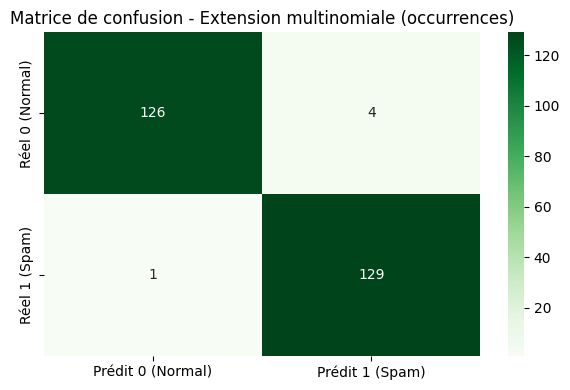

In [6]:
from sklearn.naive_bayes import MultinomialNB
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Matrices d'occurrences 
train_counts = np.zeros((numTrainDocs, numTokens))
train_counts[M[:, 0] - 1, M[:, 1] - 1] = M[:, 2]

test_counts = np.zeros((nb_test_docs, numTokens))
test_counts[M_test[:, 0].astype(int) - 1, M_test[:, 1].astype(int) - 1] = M_test[:, 2]

# Occurrences totales de chaque mot dans les spams / non-spams
occ_s  = train_counts[train_labels == 1].sum(axis=0)
occ_ns = train_counts[train_labels == 0].sum(axis=0)

# Lissage de Laplace 
p_w_s  = (occ_s  + 1) / (occ_s.sum()  + numTokens)
p_w_ns = (occ_ns + 1) / (occ_ns.sum() + numTokens)

poids_ext = np.log(p_w_s) - np.log(p_w_ns)
scores_ext = np.log(p_spam) - np.log(p_non_spam) + test_counts @ poids_ext
pred_ext = (scores_ext > 0).astype(int)

# Matrice de confusion
cm_ext = confusion_matrix(y_true, pred_ext)
cm_ext_df = pd.DataFrame(
    cm_ext,
    index=["Réel 0 (Normal)", "Réel 1 (Spam)"],
    columns=["Prédit 0 (Normal)", "Prédit 1 (Spam)"]
)
print("Matrice de confusion (extension) :\n")
print(cm_ext_df)
print(f"\nAccuracy : {accuracy_score(y_true, pred_ext):.4f} | F1 : {f1_score(y_true, pred_ext):.4f}")

# Vérification avec sklearn 
mnb = MultinomialNB(alpha=1.0).fit(train_counts, train_labels)
pred_mnb = mnb.predict(test_counts)
print("Accord avec MultinomialNB :", np.mean(pred_ext == pred_mnb))

# Graphique
plt.figure(figsize=(6, 4))
sns.heatmap(cm_ext_df, annot=True, fmt="d", cmap="Greens")
plt.title("Matrice de confusion - Extension multinomiale (occurrences)")
plt.tight_layout()
plt.show()

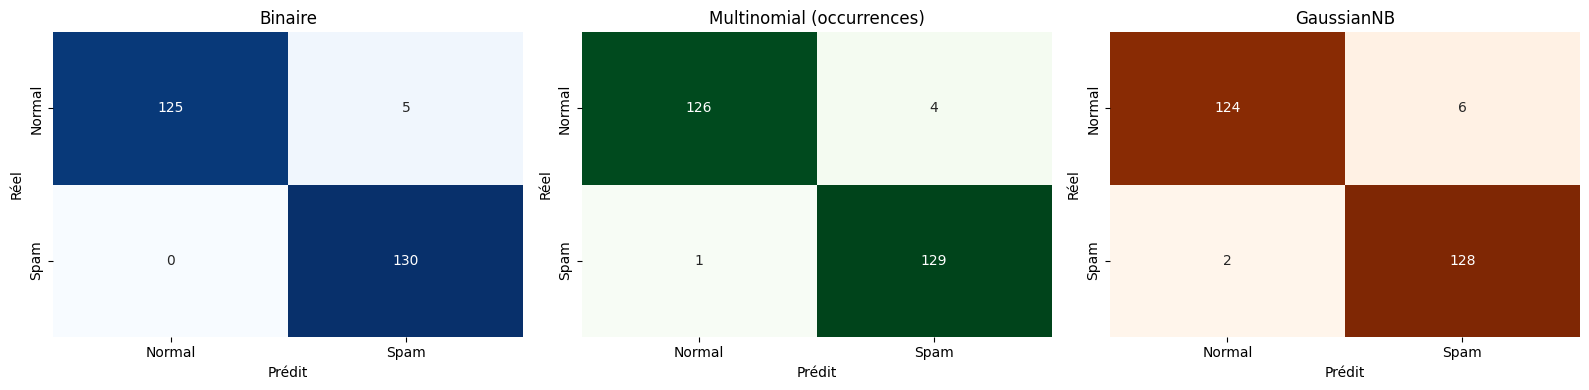

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
labels_x = ["Normal", "Spam"]

for ax, mat, titre, cmap in zip(
    axes,
    [cm, cm_ext, cm_gaussien],
    ["Binaire", "Multinomial (occurrences)", "GaussianNB"],
    ["Blues", "Greens", "Oranges"]
):
    sns.heatmap(mat, annot=True, fmt="d", cmap=cmap, ax=ax,
                xticklabels=labels_x, yticklabels=labels_x, cbar=False)
    ax.set_title(titre)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")

plt.tight_layout()
plt.show()

Le résultat est équivalent au modèle binaire (5 erreurs dans les deux cas) : on passe de 5 faux positifs et 0 faux négatif à 4 faux positifs et 1 faux négatif. Le nombre d'occurrences n'apporte donc pas de gain mesurable ici, sans doute parce que les mails sont courts et prétraités, de sorte que la présence d'un mot en dit déjà presque autant que son nombre d'occurrences. L'écart entre les deux modèles n'est pas significatif sur 260 mails de test.
Les deux approches (binaire et multinomiale) surpassent GaussianNB (96,92 %), dont l'hypothèse de variables gaussiennes est mal adaptée à des données de comptage ou de présence de mots.